In [66]:
####PERCEPTRON ÖĞRENME KURAMI####
x=[[1,1,1],
    [1,0,1],
    [0,1,1],
    [0,0,1]]

w=[0,0,0]
y=[1,0,0,0]
lr=0.5 
for j in range(100):
    print(f"-----------{j+1}. epoch-------------")
    for i in range(4):
        #1. Adım 
        u =x[i][0]*w[0]+x[i][1]*w[1]+x[i][2]*w[2]
        #2. Adım Aktivasyon Fonksiyonu
        if u>=0:ac_out=1
        else: ac_out=0
        #3. Adım Ağın Ürettiği Hatayı Hesapla
        error=y[i]-ac_out
        #4. Adım Ağırlıkları Güncelle
        w[0]=w[0]+lr*error*x[i][0]
        w[1]=w[1]+lr*error*x[i][1]
        w[2]=w[2]+lr*error*x[i][2]
        print(f"w0 ={w[0]}, w1 = {w[1]}, w2 = {w[2]}")
    print(f"Ağırlıklar [{w[0]}, {w[1]}, {w[2]}]")
        

#error=0 olduğunda dursun YAP!!!!!!!!!

-----------1. epoch-------------
w0 =0.0, w1 = 0.0, w2 = 0.0
w0 =-0.5, w1 = 0.0, w2 = -0.5
w0 =-0.5, w1 = 0.0, w2 = -0.5
w0 =-0.5, w1 = 0.0, w2 = -0.5
Ağırlıklar [-0.5, 0.0, -0.5]
-----------2. epoch-------------
w0 =0.0, w1 = 0.5, w2 = 0.0
w0 =-0.5, w1 = 0.5, w2 = -0.5
w0 =-0.5, w1 = 0.0, w2 = -1.0
w0 =-0.5, w1 = 0.0, w2 = -1.0
Ağırlıklar [-0.5, 0.0, -1.0]
-----------3. epoch-------------
w0 =0.0, w1 = 0.5, w2 = -0.5
w0 =0.0, w1 = 0.5, w2 = -0.5
w0 =0.0, w1 = 0.0, w2 = -1.0
w0 =0.0, w1 = 0.0, w2 = -1.0
Ağırlıklar [0.0, 0.0, -1.0]
-----------4. epoch-------------
w0 =0.5, w1 = 0.5, w2 = -0.5
w0 =0.0, w1 = 0.5, w2 = -1.0
w0 =0.0, w1 = 0.5, w2 = -1.0
w0 =0.0, w1 = 0.5, w2 = -1.0
Ağırlıklar [0.0, 0.5, -1.0]
-----------5. epoch-------------
w0 =0.5, w1 = 1.0, w2 = -0.5
w0 =0.0, w1 = 1.0, w2 = -1.0
w0 =0.0, w1 = 0.5, w2 = -1.5
w0 =0.0, w1 = 0.5, w2 = -1.5
Ağırlıklar [0.0, 0.5, -1.5]
-----------6. epoch-------------
w0 =0.5, w1 = 1.0, w2 = -1.0
w0 =0.5, w1 = 1.0, w2 = -1.0
w0 =0.5, w1 = 0.5,

In [67]:
########MLP
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report,confusion_matrix


In [68]:
#
iris=load_iris()
x=iris.data
y=iris.target


In [69]:
XTrain,XTest,yTrain,yTest=train_test_split(x,y,test_size=0.2,random_state=1)


In [70]:
#verileri standartlaştır
scaler=StandardScaler()

XTrain=scaler.fit_transform(XTrain)
XTest=scaler.fit_transform(XTest)



In [71]:
model=MLPClassifier(solver="adam",activation="relu",learning_rate="adaptive",learning_rate_init=0.005,hidden_layer_sizes=(100),verbose=True,max_iter=100,early_stopping=True)
model.fit(XTrain,yTrain)

Iteration 1, loss = 0.99753554
Validation score: 0.416667
Iteration 2, loss = 0.90945365
Validation score: 0.500000
Iteration 3, loss = 0.83109966
Validation score: 0.500000
Iteration 4, loss = 0.76223439
Validation score: 0.500000
Iteration 5, loss = 0.70218983
Validation score: 0.500000
Iteration 6, loss = 0.65059073
Validation score: 0.583333
Iteration 7, loss = 0.60610089
Validation score: 0.583333
Iteration 8, loss = 0.56780780
Validation score: 0.583333
Iteration 9, loss = 0.53480968
Validation score: 0.583333
Iteration 10, loss = 0.50613983
Validation score: 0.666667
Iteration 11, loss = 0.48091564
Validation score: 0.666667
Iteration 12, loss = 0.45847837
Validation score: 0.666667
Iteration 13, loss = 0.43839911
Validation score: 0.750000
Iteration 14, loss = 0.42029555
Validation score: 0.750000
Iteration 15, loss = 0.40390083
Validation score: 0.833333
Iteration 16, loss = 0.38897061
Validation score: 0.833333
Iteration 17, loss = 0.37527245
Validation score: 0.833333
Iterat

MLPClassifier(early_stopping=True, hidden_layer_sizes=100,
              learning_rate='adaptive', learning_rate_init=0.005, max_iter=100,
              verbose=True)

In [72]:
#tahmin yap
predictions=model.predict(XTest)

print(confusion_matrix(yTest,predictions))
print(classification_report(yTest,predictions))

[[11  0  0]
 [ 0  6  7]
 [ 0  0  6]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.46      0.63        13
           2       0.46      1.00      0.63         6

    accuracy                           0.77        30
   macro avg       0.82      0.82      0.75        30
weighted avg       0.89      0.77      0.77        30



In [73]:
iris=load_iris()
X=iris.data
y=iris.target

In [74]:
#modeli kendimiz eğitiyoruz (MLPyi kendimiz yazdık)
XTrain,XTest,yTrain,yTest=train_test_split(X,y,test_size=0.2,random_state=1)
XTrain,XVal,yTrain,yVal=train_test_split(XTrain,yTrain,test_size=0.2,random_state=1)


scaler=StandardScaler()

XTrain=scaler.fit_transform(XTrain)
XTest=scaler.fit_transform(XTest)
XVal=scaler.fit_transform(XVal)

In [75]:
from re import VERBOSE
from tensorflow.keras import layers,models

model=models.Sequential()
model.add(layers.Dense(10,activation='relu',input_shape=(4,))) #giriş katmanı
model.add(layers.Dense(50,activation='relu')) #hidden layer
model.add(layers.Dense(3,activation='softmax')) #çıkış layer

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history=model.fit(XTrain,yTrain,epochs=100,verbose=True,validation_data=(XVal,yVal))

Epoch 1/100


3/3 [==============================] - 0s 58ms/step - loss: 1.0616 - accuracy: 0.2812 - val_loss: 1.0349 - val_accuracy: 0.4583
Epoch 2/100
3/3 [==============================] - 0s 8ms/step - loss: 1.0299 - accuracy: 0.3750 - val_loss: 1.0013 - val_accuracy: 0.5417
Epoch 3/100
3/3 [==============================] - 0s 8ms/step - loss: 1.0015 - accuracy: 0.5208 - val_loss: 0.9686 - val_accuracy: 0.6667
Epoch 4/100
3/3 [==============================] - 0s 3ms/step - loss: 0.9709 - accuracy: 0.6042 - val_loss: 0.9373 - val_accuracy: 0.7083
Epoch 5/100
3/3 [==============================] - 0s 9ms/step - loss: 0.9425 - accuracy: 0.6458 - val_loss: 0.9068 - val_accuracy: 0.7500
Epoch 6/100
3/3 [==============================] - 0s 7ms/step - loss: 0.9135 - accuracy: 0.6667 - val_loss: 0.8779 - val_accuracy: 0.7500
Epoch 7/100
3/3 [==============================] - 0s 8ms/step - loss: 0.8888 - accuracy: 0.6667 - val_loss: 0.8489 - val_accuracy: 0.7500
Epoch 8/100
3/3 [=====================

TypeError: 'str' object is not callable

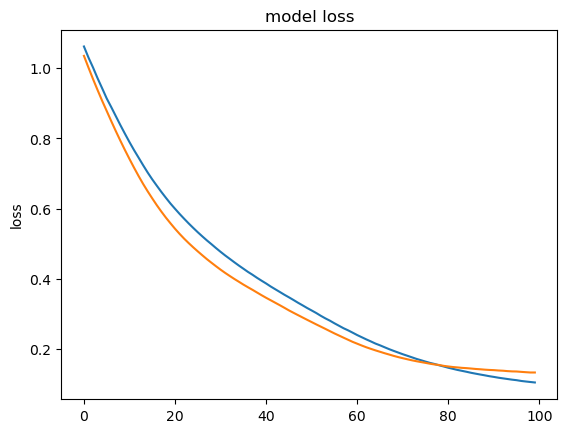

In [76]:
#İLK GÖRMEK İSTENİLEN GRAFİK BUDUR. 
from matplotlib import pyplot as plt 
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','val'],loc='upper left')
plt.show()

1/1 [==============================] - 0s 38ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.62      0.76        13
           2       0.55      1.00      0.71         6

    accuracy                           0.83        30
   macro avg       0.85      0.87      0.82        30
weighted avg       0.91      0.83      0.84        30



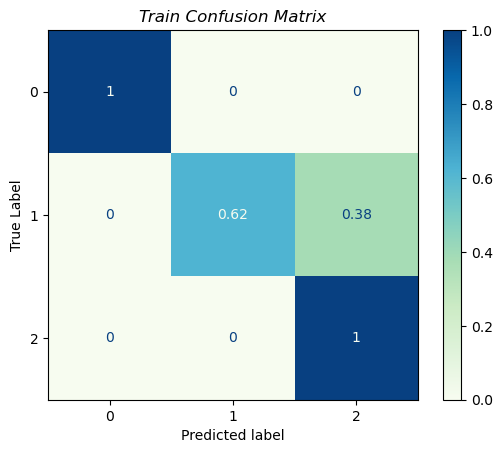

In [77]:
from sklearn.metrics import classification_report,ConfusionMatrixDisplay,confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
yTestPred=model.predict(XTest)
yTestPred=np.argmax(yTestPred,axis=1)
yTest=np.asarray(yTest)
print(classification_report(yTest,yTestPred))
cm=confusion_matrix(yTest,yTestPred,normalize="true").round(2)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp=disp.plot(cmap=plt.cm.GnBu, values_format='g')
plt.title(f"Train Confusion Matrix", style="italic")
plt.xlabel=("Predicted Label")
plt.ylabel("True Label")
plt.show()